# Wavelength Ablation — S2 defaults vs. true sensor wavelengths

Compares frozen-encoder performance when feeding the encoder the true sensor central wavelengths (PlanetScope / GaoFen-2 / Landsat-8) versus the default S2 band names.

**Datasets / sensors:**
| Dataset | Sensor | Bands | Task | Metric |
|---------|--------|-------|------|--------|
| SpaceNet7-CD | PlanetScope PS2 | RGB | binary change detection | mIoU |
| FiveBillionPixels | GaoFen-2 PMS | NIR+RGB | 25-class segmentation | mIoU |
| m-Forestnet | Landsat-8 OLI | 6 bands | 12-class classification | Accuracy |

**S2 baselines** source per dataset:
- SpaceNet7-CD → `pangaea_full_seg/upernet/{enc_seg}/` (regular benchmark runs)
- FiveBillionPixels → `pangaea_full_seg/upernet/{enc_seg}/` (regular benchmark runs)
- m-Forestnet → `geobench/cls/{enc_cls}/` (regular benchmark runs)

In [1]:
import re
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

EXPERIMENTS_BASE = Path("/dss/dsstbyfs02/pn49cu/pn49cu-dss-0001/niklas/experiments")
WL_ABL_BASE = EXPERIMENTS_BASE / "wavelength_ablation"
WL_MLF_BASE = EXPERIMENTS_BASE / "wavelength_ablation_mlpfusion"

# wl_ablation subfolder → (display_name, upernet_s2_subdir, cls_s2_subdir, mlp_s2_subdir)
WL_FOLDER_INFO = {
    "dofa_wl_ablation":       ("DOFA",             "dofa_seg",               "dofa",              "dofa_mlp_fusion"),
    "dofav2_wl_ablation":     ("DOFAv2",           "dofav2_seg",             "dofav2",            "dofav2_mlp_fusion"),
    "panopticon_wl_ablation": ("Panopticon",       "panopticon_seg",         "panopticon",        "panopticon_mlp_fusion"),
    "sm_wl_ablation":         ("SMARTIES",         "smarties_vitb_seg",      "smarties_vitb",     "smarties_vitb_mlp_fusion"),
    "cfm_wl_ablation":        ("Copernicus-FM",    "copernicus_fm_base_seg", "copernicus_fm_base","copernicus_fm_base_mlp_fusion"),
    "carl_dw_wl_ablation":    ("CARL (dset-norm)", "carl_seg",               "carl",              "carl_mlp_fusion"),
    "carl_iw_wl_ablation":    ("CARL (img-norm)",  "carl_imagewise_seg",     "carl_imagewise",    "carl_imagewise_mlp_fusion"),
}

ENCODER_ORDER = [
    "DOFA", "DOFAv2", "Panopticon", "SMARTIES", "Copernicus-FM",
    "CARL (dset-norm)", "CARL (img-norm)",
]

# Substrings in tw run-dir names → (dataset display name, primary metric key)
# Longer keys first so 'spacenet7cd_true_wl' is matched before any shorter key
DS_FROM_DIR = {
    "spacenet7cd_true_wl":       ("SpaceNet7-CD",      "mIoU"),
    "fivebillionpixels_true_wl": ("FiveBillionPixels", "mIoU"),
    "mforestnet_true_wl":        ("m-Forestnet",       "Accuracy"),
}

DATASET_ORDER     = ["SpaceNet7-CD", "FiveBillionPixels", "m-Forestnet"]
DATASET_ORDER_MLF = ["SpaceNet7-CD", "FiveBillionPixels"]

print("Config loaded.")

Config loaded.


In [2]:
# ── Parse functions (same format as analyze_results) ────────────────────────

def parse_log_metrics(log_path: Path) -> dict:
    """Parse segmentation train.log-0 — returns test_mIoU, test_mF1, etc."""
    log_path = Path(log_path)
    if not log_path.exists():
        return {}
    text = log_path.read_text(errors="ignore")
    sections = re.split(r"\[test\] ------- IoU", text)
    if len(sections) < 2:
        return {}
    test_block = "[test] ------- IoU" + sections[-1]
    metrics = {}
    for section_name, key in [
        ("IoU",       "test_mIoU"),
        ("F1-score",  "test_mF1"),
        ("Precision", "test_mPrecision"),
        ("Recall",    "test_mRecall"),
    ]:
        m = re.search(
            rf"\[test\] ------- {section_name}.*?\[test\] Mean\s+([\d.]+)",
            test_block, re.DOTALL,
        )
        if m:
            metrics[key] = float(m.group(1))
    return metrics


def parse_cls_log_metrics(log_path: Path) -> dict:
    """Parse classification train.log-0 — returns test_Accuracy, test_mF1, etc."""
    log_path = Path(log_path)
    if not log_path.exists():
        return {}
    text = log_path.read_text(errors="ignore")
    sections = re.split(r"\[test\] ------- Accuracy", text)
    if len(sections) < 2:
        return {}
    test_block = "[test] ------- Accuracy" + sections[-1]
    metrics = {}
    for section_name, key in [
        ("Accuracy",  "test_Accuracy"),
        ("F1-score",  "test_mF1"),
        ("Precision", "test_Precision"),
        ("Recall",    "test_Recall"),
    ]:
        m = re.search(
            rf"\[test\] ------- {section_name}.*?\[test\] Mean\s+([\d.]+)",
            test_block, re.DOTALL,
        )
        if m:
            metrics[key] = float(m.group(1))
    return metrics

print("Parse functions defined.")

Parse functions defined.


## Band wavelengths: S2 defaults vs. true sensor

For each dataset, circles show the S2 band wavelengths the encoder *thinks* it receives; diamonds show the true sensor wavelengths. Δ = true − S2.

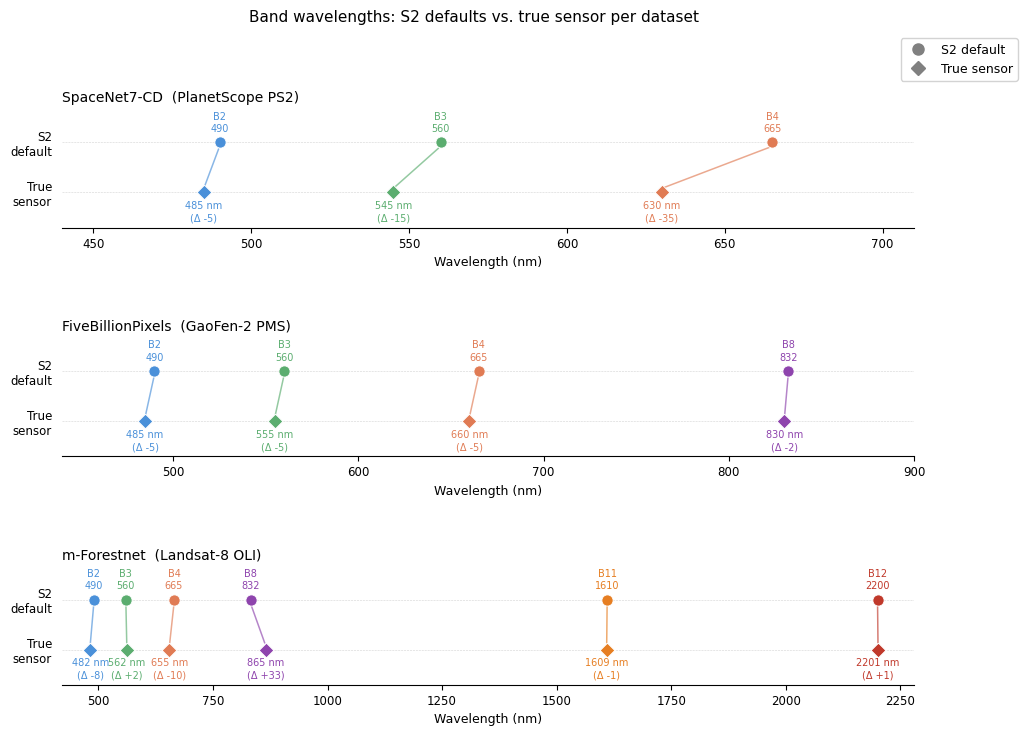

In [3]:
from collections import OrderedDict
from matplotlib.lines import Line2D

# Central wavelengths (nm) — from DOFA wave_list / sensor datasheets
BAND_WL = {
    # Sentinel-2 (encoder defaults)
    "B2": 490, "B3": 560, "B4": 665, "B8": 832, "B11": 1610, "B12": 2200,
    # PlanetScope PS2  (SpaceNet7-CD)
    "PS_Blue": 485, "PS_Green": 545, "PS_Red": 630,
    # GaoFen-2 PMS    (FiveBillionPixels)
    "GF2_Blue": 485, "GF2_Green": 555, "GF2_Red": 660, "GF2_NIR": 830,
    # Landsat-8 OLI   (m-Forestnet)
    "L8_B2": 482, "L8_B3": 562, "L8_B4": 655, "L8_B5": 865,
    "L8_B6": 1609, "L8_B7": 2201,
}

SPECTRAL_COLORS = {
    "Blue":   "#4A90D9",
    "Green":  "#5BAD6F",
    "Red":    "#E07B54",
    "NIR":    "#8E44AD",
    "SWIR-1": "#E67E22",
    "SWIR-2": "#C0392B",
}

# (s2_band, true_band, spectral_label) in order of decreasing wavelength
DATASET_BAND_PAIRS = OrderedDict([
    ("SpaceNet7-CD  (PlanetScope PS2)", [
        ("B4",  "PS_Red",    "Red"),
        ("B3",  "PS_Green",  "Green"),
        ("B2",  "PS_Blue",   "Blue"),
    ]),
    ("FiveBillionPixels  (GaoFen-2 PMS)", [
        ("B8",  "GF2_NIR",   "NIR"),
        ("B4",  "GF2_Red",   "Red"),
        ("B3",  "GF2_Green", "Green"),
        ("B2",  "GF2_Blue",  "Blue"),
    ]),
    ("m-Forestnet  (Landsat-8 OLI)", [
        ("B2",  "L8_B2", "Blue"),
        ("B3",  "L8_B3", "Green"),
        ("B4",  "L8_B4", "Red"),
        ("B8",  "L8_B5", "NIR"),
        ("B11", "L8_B6", "SWIR-1"),
        ("B12", "L8_B7", "SWIR-2"),
    ]),
])

XLIMS = {
    "SpaceNet7-CD  (PlanetScope PS2)":   (440,  710),
    "FiveBillionPixels  (GaoFen-2 PMS)": (440,  900),
    "m-Forestnet  (Landsat-8 OLI)":      (420, 2280),
}

fig, axes = plt.subplots(3, 1, figsize=(11, 7.5), gridspec_kw={"hspace": 0.9})

for ax, (ds_title, pairs) in zip(axes, DATASET_BAND_PAIRS.items()):
    ax.set_xlim(*XLIMS[ds_title])
    ax.set_ylim(-0.7, 1.7)
    ax.set_yticks([0, 1])
    ax.set_yticklabels(["True\nsensor", "S2\ndefault"], fontsize=8.5)
    ax.axhline(0, color="grey", lw=0.4, ls="--", alpha=0.35, zorder=0)
    ax.axhline(1, color="grey", lw=0.4, ls="--", alpha=0.35, zorder=0)
    ax.set_title(ds_title, fontsize=10, loc="left", pad=4)
    ax.set_xlabel("Wavelength (nm)", fontsize=9)
    ax.spines[["top", "right", "left"]].set_visible(False)
    ax.tick_params(left=False, labelsize=8.5)

    for s2_band, tw_band, label in pairs:
        wl_s2 = BAND_WL[s2_band]
        wl_tw = BAND_WL[tw_band]
        color  = SPECTRAL_COLORS[label]
        delta  = wl_tw - wl_s2
        sign   = "+" if delta > 0 else ""

        # connecting line (S2 → true sensor)
        ax.annotate("", xy=(wl_tw, 0.08), xytext=(wl_s2, 0.92),
                    arrowprops=dict(arrowstyle="-", color=color, lw=1.1, alpha=0.65))

        # S2 marker + label above
        ax.scatter(wl_s2, 1, color=color, s=65, zorder=4,
                   edgecolors="white", linewidths=0.6)
        ax.text(wl_s2, 1.17, f"{s2_band}\n{wl_s2}", ha="center", va="bottom",
                fontsize=7, color=color, linespacing=1.3)

        # True sensor marker + wavelength + Δ below
        ax.scatter(wl_tw, 0, color=color, s=55, zorder=4, marker="D",
                   edgecolors="white", linewidths=0.6)
        ax.text(wl_tw, -0.17, f"{wl_tw} nm\n(Δ {sign}{delta})", ha="center", va="top",
                fontsize=7, color=color, linespacing=1.3)

legend_elems = [
    Line2D([0], [0], marker="o", color="grey", lw=0, markersize=8, label="S2 default"),
    Line2D([0], [0], marker="D", color="grey", lw=0, markersize=7, label="True sensor"),
]
fig.legend(handles=legend_elems, loc="upper right", fontsize=9,
           framealpha=0.85, bbox_to_anchor=(1.0, 0.98))

fig.suptitle("Band wavelengths: S2 defaults vs. true sensor per dataset",
             fontsize=11, y=1.01)
fig.savefig("figures/wavelength_comparison.pdf", bbox_inches="tight")
plt.show()

In [4]:
# ── Load True-WL results (UPerNet) ───────────────────────────────────────────

def load_tw_results() -> pd.DataFrame:
    rows = []
    for folder_name, (enc_label, _, _, _) in WL_FOLDER_INFO.items():
        folder = WL_ABL_BASE / folder_name
        if not folder.exists():
            continue
        for run_dir in sorted(folder.iterdir()):
            if not run_dir.is_dir():
                continue
            ds_info = next(
                ((ds, met) for key, (ds, met) in DS_FROM_DIR.items()
                 if key in run_dir.name),
                None,
            )
            if ds_info is None:
                continue
            ds, metric_name = ds_info
            log = run_dir / "train.log-0"
            if metric_name == "Accuracy":
                parsed = parse_cls_log_metrics(log)
                val = parsed.get("test_Accuracy")
            else:
                parsed = parse_log_metrics(log)
                val = parsed.get("test_mIoU")
            if val is None:
                continue
            rows.append({
                "encoder":     enc_label,
                "dataset":     ds,
                "variant":     "True-WL",
                "metric":      val,
                "metric_name": metric_name,
                "run_dir":     run_dir.name,
            })
    return pd.DataFrame(rows)


df_tw = load_tw_results()
print(f"{len(df_tw)} True-WL results loaded")
df_tw.pivot_table(index="encoder", columns="dataset", values="metric", aggfunc="max").round(3)

19 True-WL results loaded


dataset,FiveBillionPixels,SpaceNet7-CD,m-Forestnet
encoder,,,
CARL (dset-norm),NaN,53.626,0.437
CARL (img-norm),NaN,54.271,0.471
Copernicus-FM,55.705,56.841,0.513
DOFA,67.387,59.453,0.567
DOFAv2,71.273,59.404,0.493
Panopticon,69.869,59.040,0.538
SMARTIES,56.928,58.155,0.476


In [5]:
# ── Load S2 baselines (UPerNet) ───────────────────────────────────────────────
# SpaceNet7-CD + FiveBillionPixels → pangaea_full_seg/upernet/{enc_seg}/
# m-Forestnet                      → geobench/cls/{enc_cls}/

def load_s2_baselines() -> pd.DataFrame:
    upernet_base = EXPERIMENTS_BASE / "pangaea_full_seg" / "upernet"
    cls_base     = EXPERIMENTS_BASE / "geobench" / "cls"
    rows = []
    for folder_name, (enc_label, upernet_subdir, cls_subdir, _) in WL_FOLDER_INFO.items():

        # SpaceNet7-CD + FiveBillionPixels — from pangaea_full_seg/upernet
        enc_up = upernet_base / upernet_subdir
        if enc_up.exists():
            for run_dir in sorted(enc_up.iterdir()):
                if not run_dir.is_dir():
                    continue
                name = run_dir.name
                m = parse_log_metrics(run_dir / "train.log-0")
                if "test_mIoU" not in m:
                    continue
                if "spacenet7cd" in name:
                    rows.append({
                        "encoder":     enc_label,
                        "dataset":     "SpaceNet7-CD",
                        "variant":     "S2",
                        "metric":      m["test_mIoU"],
                        "metric_name": "mIoU",
                        "run_dir":     name,
                    })
                elif "fivebillionpixels" in name:
                    rows.append({
                        "encoder":     enc_label,
                        "dataset":     "FiveBillionPixels",
                        "variant":     "S2",
                        "metric":      m["test_mIoU"],
                        "metric_name": "mIoU",
                        "run_dir":     name,
                    })

        # m-Forestnet — from geobench/cls
        enc_cls = cls_base / cls_subdir
        if enc_cls.exists():
            for run_dir in sorted(enc_cls.iterdir()):
                if not run_dir.is_dir() or "mforestnet" not in run_dir.name:
                    continue
                m = parse_cls_log_metrics(run_dir / "train.log-0")
                if "test_Accuracy" in m:
                    rows.append({
                        "encoder":     enc_label,
                        "dataset":     "m-Forestnet",
                        "variant":     "S2",
                        "metric":      m["test_Accuracy"],
                        "metric_name": "Accuracy",
                        "run_dir":     run_dir.name,
                    })
    return pd.DataFrame(rows)


df_s2 = load_s2_baselines()
print(f"{len(df_s2)} S2 baseline results loaded")
df_s2.pivot_table(index="encoder", columns="dataset", values="metric", aggfunc="max").round(3)

23 S2 baseline results loaded


dataset,FiveBillionPixels,SpaceNet7-CD,m-Forestnet
encoder,,,
CARL (dset-norm),50.723,59.131,0.442
CARL (img-norm),47.587,58.069,0.309
Copernicus-FM,62.801,62.360,0.519
DOFA,69.929,61.068,0.560
DOFAv2,71.216,63.634,0.505
Panopticon,70.096,60.769,0.555
SMARTIES,57.318,59.508,0.506


In [6]:
# ── Load MLP-Fusion True-WL results ──────────────────────────────────────────

def load_mlp_results() -> pd.DataFrame:
    rows = []
    for folder_name, (enc_label, _, _, _) in WL_FOLDER_INFO.items():
        folder = WL_MLF_BASE / folder_name
        if not folder.exists():
            continue
        for run_dir in sorted(folder.iterdir()):
            if not run_dir.is_dir():
                continue
            ds_info = next(
                ((ds, met) for key, (ds, met) in DS_FROM_DIR.items()
                 if key in run_dir.name),
                None,
            )
            if ds_info is None:
                continue
            ds, metric_name = ds_info
            log = run_dir / "train.log-0"
            if metric_name == "Accuracy":
                parsed = parse_cls_log_metrics(log)
                val = parsed.get("test_Accuracy")
            else:
                parsed = parse_log_metrics(log)
                val = parsed.get("test_mIoU")
            if val is None:
                continue
            rows.append({
                "encoder":     enc_label,
                "dataset":     ds,
                "variant":     "MLP-WL",
                "metric":      val,
                "metric_name": metric_name,
                "run_dir":     run_dir.name,
            })
    return pd.DataFrame(rows)


df_mlp = load_mlp_results()
print(f"{len(df_mlp)} MLP-Fusion True-WL results loaded")
df_mlp.pivot_table(index="encoder", columns="dataset", values="metric", aggfunc="max").round(3)

14 MLP-Fusion True-WL results loaded


dataset,FiveBillionPixels,SpaceNet7-CD
encoder,,
CARL (dset-norm),45.799,54.203
CARL (img-norm),43.446,52.284
Copernicus-FM,50.179,51.702
DOFA,64.620,54.979
DOFAv2,66.443,54.700
Panopticon,66.184,56.724
SMARTIES,51.815,52.500


## UPerNet — Comparison tables

For each dataset: S2 baseline, True-WL result, and Δ (True-WL − S2). Positive Δ means true wavelengths helped.

In [7]:
df_all = pd.concat([df_s2, df_tw], ignore_index=True)


def make_comparison_table(df: pd.DataFrame, dataset: str, metric_label: str) -> pd.DataFrame | None:
    sub = df[df["dataset"] == dataset]
    if sub.empty:
        print(f"  No data for {dataset}")
        return None
    pivot = sub.pivot_table(
        index="encoder", columns="variant", values="metric", aggfunc="max"
    )
    col_order = [c for c in ["S2", "True-WL"] if c in pivot.columns]
    pivot = pivot[col_order].copy()
    if "S2" in pivot.columns and "True-WL" in pivot.columns:
        pivot["Δ (TW − S2)"] = (pivot["True-WL"] - pivot["S2"]).round(2)
    order = [e for e in ENCODER_ORDER if e in pivot.index]
    pivot = pivot.reindex(order).round(3)
    pivot.columns.name = f"{dataset}  [{metric_label}]"
    return pivot


for ds, met in [("SpaceNet7-CD", "mIoU"), ("FiveBillionPixels", "mIoU"), ("m-Forestnet", "Accuracy")]:
    t = make_comparison_table(df_all, ds, met)
    if t is not None:
        display(t)

SpaceNet7-CD [mIoU],S2,True-WL,Δ (TW − S2)
encoder,,,
DOFA,61.068,59.453,-1.61
DOFAv2,63.634,59.404,-4.23
Panopticon,60.769,59.040,-1.73
SMARTIES,59.508,58.155,-1.35
Copernicus-FM,62.360,56.841,-5.52
CARL (dset-norm),59.131,53.626,-5.51
CARL (img-norm),58.069,54.271,-3.80


FiveBillionPixels [mIoU],S2,True-WL,Δ (TW − S2)
encoder,,,
DOFA,69.929,67.387,-2.54
DOFAv2,71.216,71.273,0.06
Panopticon,70.096,69.869,-0.23
SMARTIES,57.318,56.928,-0.39
Copernicus-FM,62.801,55.705,-7.10
CARL (dset-norm),50.723,NaN,NaN
CARL (img-norm),47.587,NaN,NaN


m-Forestnet [Accuracy],S2,True-WL,Δ (TW − S2)
encoder,,,
DOFA,0.560,0.567,0.01
DOFAv2,0.505,0.493,-0.01
Panopticon,0.555,0.538,-0.02
SMARTIES,0.506,0.476,-0.03
Copernicus-FM,0.519,0.513,-0.01
CARL (dset-norm),0.442,0.437,-0.01
CARL (img-norm),0.309,0.471,0.16


## UPerNet — Delta heatmap

Δ = True-WL metric − S2 metric per encoder × dataset.  
Blue = true wavelengths help; red = S2 defaults were better.

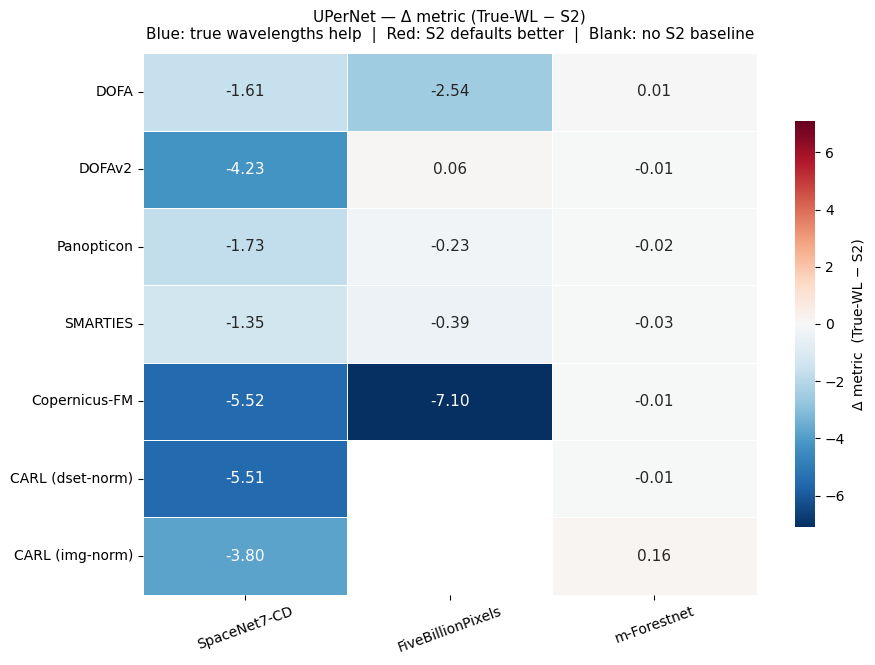

In [8]:
s2_pivot = df_s2.pivot_table(index="encoder", columns="dataset", values="metric", aggfunc="max")
tw_pivot = df_tw.pivot_table(index="encoder", columns="dataset", values="metric", aggfunc="max")

s2_aligned, tw_aligned = s2_pivot.align(tw_pivot, join="outer")
delta = (tw_aligned - s2_aligned).round(2)
delta = delta.reindex(
    index=[e for e in ENCODER_ORDER if e in delta.index],
    columns=[d for d in DATASET_ORDER if d in delta.columns],
)

fig, ax = plt.subplots(figsize=(len(delta.columns) * 2.6 + 1.5, len(delta) * 0.65 + 2.2))

vmax = max(1.0, float(delta.abs().max().max()))
sns.heatmap(
    delta, ax=ax,
    cmap="RdBu_r", center=0, vmin=-vmax, vmax=vmax,
    annot=True, fmt=".2f", annot_kws={"size": 11},
    linewidths=0.5, linecolor="white",
    cbar_kws={"label": "Δ metric  (True-WL − S2)", "shrink": 0.75},
)
ax.set_title(
    "UPerNet — Δ metric (True-WL − S2)\n"
    "Blue: true wavelengths help  |  Red: S2 defaults better  |  Blank: no S2 baseline",
    fontsize=11, pad=10,
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=20, labelsize=10)
ax.tick_params(axis="y", rotation=0,  labelsize=10)
fig.tight_layout()
fig.savefig("figures/wavelength_ablation_delta_heatmap_upernet.pdf", bbox_inches="tight")
plt.show()

## UPerNet — Grouped bar chart — S2 vs. True-WL per encoder × dataset

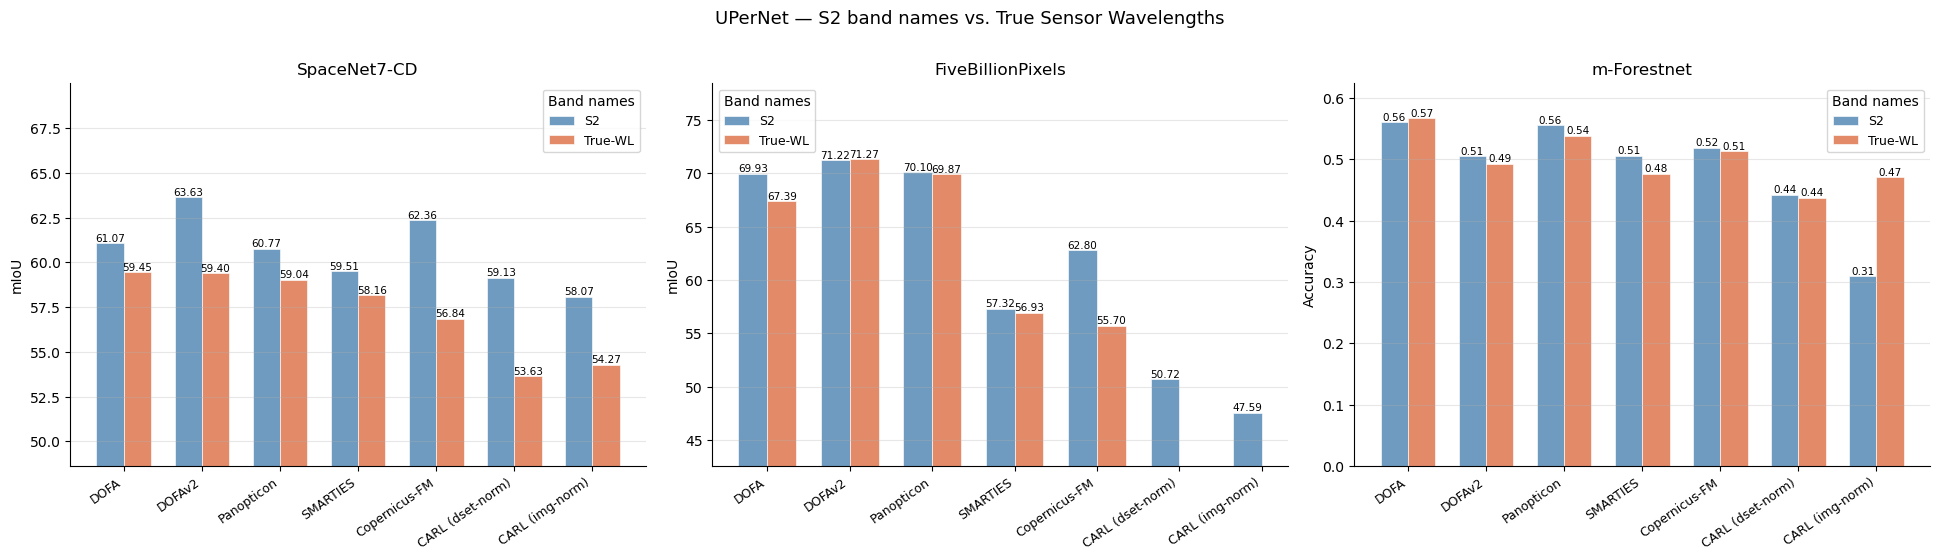

In [19]:
datasets_with_s2 = ["SpaceNet7-CD", "FiveBillionPixels", "m-Forestnet"]
metric_labels = {
    "SpaceNet7-CD":      "mIoU",
    "FiveBillionPixels": "mIoU",
    "m-Forestnet":       "Accuracy",
}

fig, axes = plt.subplots(1, len(datasets_with_s2), figsize=(6.5 * len(datasets_with_s2), 5.5), sharey=False)

palette = {"S2": "#5B8DB8", "True-WL": "#E07B54"}

for ax, ds in zip(axes, datasets_with_s2):
    sub = df_all[df_all["dataset"] == ds].copy()
    enc_present = [e for e in ENCODER_ORDER if e in sub["encoder"].unique()]
    sub = sub[sub["encoder"].isin(enc_present)]
    sub = sub.groupby(["encoder", "variant"], as_index=False)["metric"].max()

    x = np.arange(len(enc_present))
    width = 0.35
    for i, variant in enumerate(["S2", "True-WL"]):
        vals = [
            sub.loc[(sub["encoder"] == e) & (sub["variant"] == variant), "metric"].values
            for e in enc_present
        ]
        heights = [v[0] if len(v) > 0 else np.nan for v in vals]
        bars = ax.bar(
            x + (i - 0.5) * width, heights, width,
            label=variant, color=palette[variant], alpha=0.88,
            edgecolor="white", linewidth=0.5,
        )
        for bar, h in zip(bars, heights):
            if not np.isnan(h):
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_height(),
                    f"{h:.2f}",
                    ha="center", va="bottom", fontsize=7.5,
                )

    ax.set_xticks(x)
    ax.set_xticklabels(enc_present, rotation=35, ha="right", fontsize=9)
    ax.set_ylabel(metric_labels[ds])
    ax.set_title(ds)
    ax.legend(title="Band names", fontsize=9)
    present_vals = sub["metric"].dropna()
    if len(present_vals):
        ax.set_ylim(
            bottom=max(0, present_vals.min() - 5),
            top=present_vals.max()*1.1,
        )
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("UPerNet — S2 band names vs. True Sensor Wavelengths", fontsize=13, y=1.01)
fig.tight_layout()
fig.savefig("figures/wavelength_ablation_bars_upernet.png", bbox_inches="tight")
plt.show()

---
## MLP-Fusion decoder — S2 defaults vs. True Wavelengths

Same ablation as above but using the MLP-Fusion decoder (SN7-CD + FiveBillionPixels only).  
S2 baselines come from `pangaea_full_seg/mlp_fusion/`.

In [10]:
# ── Load MLP-Fusion S2 baselines ─────────────────────────────────────────────
# SN7-CD + FiveBillionPixels → pangaea_full_seg/mlp_fusion/{enc}_mlp_fusion/

def load_mlp_s2_baselines() -> pd.DataFrame:
    mlp_base = EXPERIMENTS_BASE / "pangaea_full_seg" / "mlp_fusion"
    rows = []
    for folder_name, (enc_label, _, _, mlp_subdir) in WL_FOLDER_INFO.items():
        enc_dir = mlp_base / mlp_subdir
        if not enc_dir.exists():
            continue
        for run_dir in sorted(enc_dir.iterdir()):
            if not run_dir.is_dir():
                continue
            name = run_dir.name
            m = parse_log_metrics(run_dir / "train.log-0")
            if "test_mIoU" not in m:
                continue
            if "spacenet7cd" in name:
                rows.append({
                    "encoder":     enc_label,
                    "dataset":     "SpaceNet7-CD",
                    "variant":     "S2",
                    "metric":      m["test_mIoU"],
                    "metric_name": "mIoU",
                    "run_dir":     name,
                })
            elif "fivebillionpixels" in name:
                rows.append({
                    "encoder":     enc_label,
                    "dataset":     "FiveBillionPixels",
                    "variant":     "S2",
                    "metric":      m["test_mIoU"],
                    "metric_name": "mIoU",
                    "run_dir":     name,
                })
    return pd.DataFrame(rows)


df_mlp_s2 = load_mlp_s2_baselines()
print(f"{len(df_mlp_s2)} MLP-Fusion S2 baseline results loaded")
df_mlp_s2.pivot_table(index="encoder", columns="dataset", values="metric", aggfunc="max").round(3)

14 MLP-Fusion S2 baseline results loaded


dataset,FiveBillionPixels,SpaceNet7-CD
encoder,,
CARL (dset-norm),46.000,57.489
CARL (img-norm),43.634,49.870
Copernicus-FM,59.123,57.401
DOFA,66.902,57.028
DOFAv2,66.861,57.030
Panopticon,66.215,58.505
SMARTIES,51.770,49.781


In [11]:
df_mlp_all = pd.concat([df_mlp_s2, df_mlp], ignore_index=True)

for ds, met in [("SpaceNet7-CD", "mIoU"), ("FiveBillionPixels", "mIoU")]:
    sub = df_mlp_all[df_mlp_all["dataset"] == ds]
    if sub.empty:
        print(f"  No data for {ds}")
        continue
    pivot = sub.pivot_table(index="encoder", columns="variant", values="metric", aggfunc="max")
    col_order = [c for c in ["S2", "MLP-WL"] if c in pivot.columns]
    pivot = pivot[col_order].copy()
    if "S2" in pivot.columns and "MLP-WL" in pivot.columns:
        pivot["Δ (MLP-WL − S2)"] = (pivot["MLP-WL"] - pivot["S2"]).round(2)
    pivot = pivot.reindex([e for e in ENCODER_ORDER if e in pivot.index]).round(3)
    pivot.columns.name = f"{ds}  [{met}]"
    display(pivot)

SpaceNet7-CD [mIoU],S2,MLP-WL,Δ (MLP-WL − S2)
encoder,,,
DOFA,57.028,54.979,-2.05
DOFAv2,57.030,54.700,-2.33
Panopticon,58.505,56.724,-1.78
SMARTIES,49.781,52.500,2.72
Copernicus-FM,57.401,51.702,-5.70
CARL (dset-norm),57.489,54.203,-3.29
CARL (img-norm),49.870,52.284,2.41


FiveBillionPixels [mIoU],S2,MLP-WL,Δ (MLP-WL − S2)
encoder,,,
DOFA,66.902,64.620,-2.28
DOFAv2,66.861,66.443,-0.42
Panopticon,66.215,66.184,-0.03
SMARTIES,51.770,51.815,0.04
Copernicus-FM,59.123,50.179,-8.94
CARL (dset-norm),46.000,45.799,-0.20
CARL (img-norm),43.634,43.446,-0.19


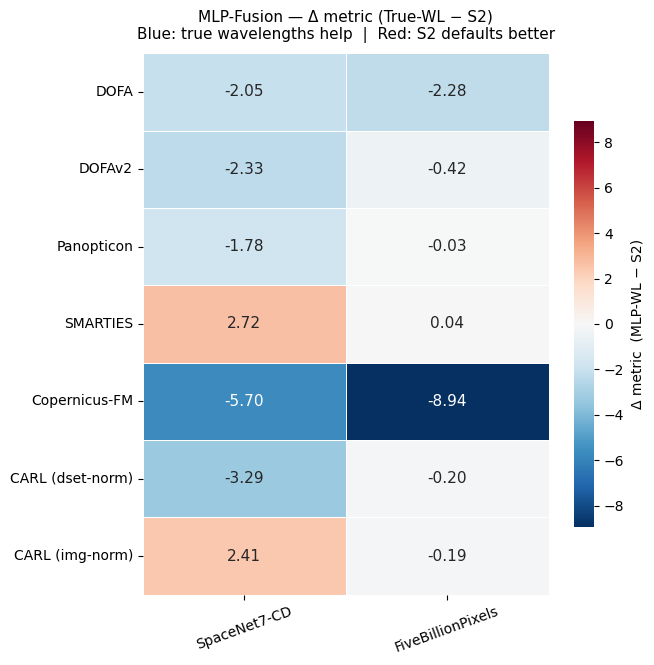

In [12]:
s2_mlp_pivot  = df_mlp_s2.pivot_table(index="encoder", columns="dataset", values="metric", aggfunc="max")
mlp_pivot      = df_mlp.pivot_table(index="encoder", columns="dataset", values="metric", aggfunc="max")

s2_aligned, mlp_aligned = s2_mlp_pivot.align(mlp_pivot, join="outer")
delta_mlp = (mlp_aligned - s2_aligned).round(2)
delta_mlp = delta_mlp.reindex(
    index=[e for e in ENCODER_ORDER if e in delta_mlp.index],
    columns=[d for d in DATASET_ORDER_MLF if d in delta_mlp.columns],
)

fig, ax = plt.subplots(figsize=(len(delta_mlp.columns) * 2.6 + 1.5, len(delta_mlp) * 0.65 + 2.2))

vmax = max(1.0, float(delta_mlp.abs().max().max()))
sns.heatmap(
    delta_mlp, ax=ax,
    cmap="RdBu_r", center=0, vmin=-vmax, vmax=vmax,
    annot=True, fmt=".2f", annot_kws={"size": 11},
    linewidths=0.5, linecolor="white",
    cbar_kws={"label": "Δ metric  (MLP-WL − S2)", "shrink": 0.75},
)
ax.set_title(
    "MLP-Fusion — Δ metric (True-WL − S2)\n"
    "Blue: true wavelengths help  |  Red: S2 defaults better",
    fontsize=11, pad=10,
)
ax.set_xlabel("")
ax.set_ylabel("")
ax.tick_params(axis="x", rotation=20, labelsize=10)
ax.tick_params(axis="y", rotation=0,  labelsize=10)
fig.tight_layout()
fig.savefig("figures/wavelength_ablation_delta_heatmap_mlpfusion.pdf", bbox_inches="tight")
plt.show()

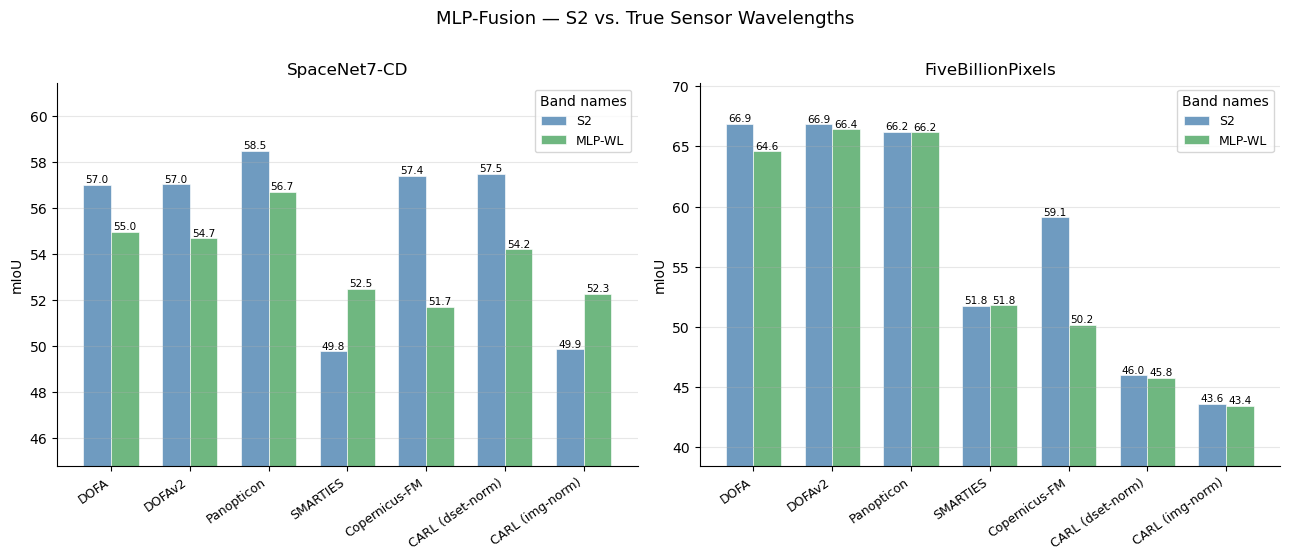

In [18]:
mlf_metric_labels = {"SpaceNet7-CD": "mIoU", "FiveBillionPixels": "mIoU"}

fig, axes = plt.subplots(1, len(DATASET_ORDER_MLF), figsize=(6.5 * len(DATASET_ORDER_MLF), 5.5), sharey=False)

palette = {"S2": "#5B8DB8", "MLP-WL": "#5BAD6F"}

for ax, ds in zip(axes, DATASET_ORDER_MLF):
    sub = df_mlp_all[df_mlp_all["dataset"] == ds].copy()
    enc_present = [e for e in ENCODER_ORDER if e in sub["encoder"].unique()]
    sub = sub[sub["encoder"].isin(enc_present)]
    sub = sub.groupby(["encoder", "variant"], as_index=False)["metric"].max()

    x = np.arange(len(enc_present))
    width = 0.35
    for i, variant in enumerate(["S2", "MLP-WL"]):
        vals = [
            sub.loc[(sub["encoder"] == e) & (sub["variant"] == variant), "metric"].values
            for e in enc_present
        ]
        heights = [v[0] if len(v) > 0 else np.nan for v in vals]
        bars = ax.bar(
            x + (i - 0.5) * width, heights, width,
            label=variant, color=palette[variant], alpha=0.88,
            edgecolor="white", linewidth=0.5,
        )
        for bar, h in zip(bars, heights):
            if not np.isnan(h):
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    bar.get_height(),
                    f"{h:.1f}",
                    ha="center", va="bottom", fontsize=7.5,
                )

    ax.set_xticks(x)
    ax.set_xticklabels(enc_present, rotation=35, ha="right", fontsize=9)
    ax.set_ylabel(mlf_metric_labels[ds])
    ax.set_title(ds)
    ax.legend(title="Band names", fontsize=9)
    ax.set_ylim(bottom=max(0, sub["metric"].min() - 5))
    ax.grid(axis="y", alpha=0.3)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("MLP-Fusion — S2 vs. True Sensor Wavelengths", fontsize=13, y=1.01)
fig.tight_layout()
fig.savefig("figures/wavelength_ablation_bars_mlpfusion.pdf", bbox_inches="tight")
plt.show()